# Yoga Recognition and Posture-Correction Pipeline

This notebook builds a practical six-stage pipeline:

1. **MediaPipe** landmark extraction from images and sampled video frames.
2. **Missing-joint handling** using opposite-side symmetry estimates and previous-frame fallback.
3. **MLP and Random Forest** frame-level classifiers.
4. **HMM + Viterbi** temporal smoothing/sequence decoding.
5. **Joint-angle evaluation** against configurable reference ranges.
6. **Text feedback** for posture deviations, with an optional text-to-speech hook.

## Dataset and labeling requirements

The earlier cells infer a label from the folder containing each image/video. This works for **pose-labeled images** and **videos where every sampled frame depicts the same pose**.

For HMM to learn transitions between different poses, the training data must have **frame-level pose labels** for videos. If a whole video is labeled only as `TreePose`, all frames inherit that label and the HMM cannot learn transitions like `TreePose_A -> TreePose_B`. For full yoga sequences, create a CSV with columns `video_id,frame_index,pose_label` (optional `yoga_label`) and use it in the annotation cell below.

Posture-angle reference ranges are examples/placeholders and must be set for your yoga pose definitions. Estimated/occluded landmarks are not ground truth; the notebook reduces trust in feedback when landmarks are imputed.


In [44]:
!pip install -q kagglehub

import kagglehub
import os

# Download the latest dataset version
path = kagglehub.dataset_download("tr1gg3rtrash/yoga-posture-dataset")

print("Path to dataset files:", path)
print("\nFiles and folders:")

for item in os.listdir(path):
    print(item)

Path to dataset files: C:\Users\Vidhansh\.cache\kagglehub\datasets\tr1gg3rtrash\yoga-posture-dataset\versions\1

Files and folders:
Adho Mukha Svanasana
Adho Mukha Vrksasana
Alanasana
Anjaneyasana
Ardha Chandrasana
Ardha Matsyendrasana
Ardha Navasana
Ardha Pincha Mayurasana
Ashta Chandrasana
Baddha Konasana
Bakasana
Balasana
Bitilasana
Camatkarasana
Dhanurasana
Eka Pada Rajakapotasana
Garudasana
Halasana
Hanumanasana
Malasana
Marjaryasana
Navasana
Padmasana
Parsva Virabhadrasana
Parsvottanasana
Paschimottanasana
Phalakasana
Pincha Mayurasana
Poses.json
Salamba Bhujangasana
Salamba Sarvangasana
Setu Bandha Sarvangasana
Sivasana
Supta Kapotasana
Trikonasana
Upavistha Konasana
Urdhva Dhanurasana
Urdhva Mukha Svsnssana
Ustrasana
Utkatasana
Uttanasana
Utthita Hasta Padangusthasana
Utthita Parsvakonasana
Vasisthasana
Virabhadrasana One
Virabhadrasana Three
Virabhadrasana Two
Vrksasana


In [45]:
for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    # Limit output to avoid printing the entire dataset
    if level >= 2:
        dirs.clear()

1/
    Poses.json
    Adho Mukha Svanasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Adho Mukha Vrksasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Alanasana/
        File1.jpeg
        File10.jpeg
        File11.png
        File12.jpeg
        File13.png
    Anjaneyasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Ardha Chandrasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Ardha Matsyendrasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Ardha Navasana/
        File1.jpeg
        File10.jpeg
        File11.jpeg
        File12.png
        File13.jpg
    Ardha Pincha Mayurasana/
        File1.png
        File10.png
        File11.png
        File12.png
        File13.png
    Ashta Chandrasana/
        File1.jpeg

In [46]:
# Quick inventory of the dataset. This works for image-only, video-only,
# or mixed datasets (unlike image_dataset_from_directory, which ignores videos).
import os

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
video_extensions = (".mp4", ".mov", ".avi", ".mkv", ".mpeg", ".mpg")
image_count = 0
video_count = 0
top_level_folders = []

for item in os.listdir(path):
    full_path = os.path.join(path, item)
    if os.path.isdir(full_path):
        top_level_folders.append(item)

for root, _, files in os.walk(path):
    for name in files:
        ext = os.path.splitext(name)[1].lower()
        image_count += ext in image_extensions
        video_count += ext in video_extensions

print("Dataset directory:", path)
print("Top-level folders:", top_level_folders)
print("Images:", image_count)
print("Videos:", video_count)

Dataset directory: C:\Users\Vidhansh\.cache\kagglehub\datasets\tr1gg3rtrash\yoga-posture-dataset\versions\1
Top-level folders: ['Adho Mukha Svanasana', 'Adho Mukha Vrksasana', 'Alanasana', 'Anjaneyasana', 'Ardha Chandrasana', 'Ardha Matsyendrasana', 'Ardha Navasana', 'Ardha Pincha Mayurasana', 'Ashta Chandrasana', 'Baddha Konasana', 'Bakasana', 'Balasana', 'Bitilasana', 'Camatkarasana', 'Dhanurasana', 'Eka Pada Rajakapotasana', 'Garudasana', 'Halasana', 'Hanumanasana', 'Malasana', 'Marjaryasana', 'Navasana', 'Padmasana', 'Parsva Virabhadrasana', 'Parsvottanasana', 'Paschimottanasana', 'Phalakasana', 'Pincha Mayurasana', 'Salamba Bhujangasana', 'Salamba Sarvangasana', 'Setu Bandha Sarvangasana', 'Sivasana', 'Supta Kapotasana', 'Trikonasana', 'Upavistha Konasana', 'Urdhva Dhanurasana', 'Urdhva Mukha Svsnssana', 'Ustrasana', 'Utkatasana', 'Uttanasana', 'Utthita Hasta Padangusthasana', 'Utthita Parsvakonasana', 'Vasisthasana', 'Virabhadrasana One', 'Virabhadrasana Three', 'Virabhadrasana T

In [1]:
import matplotlib.pyplot as plt
import cv2

# Preview one image if the dataset contains images; video-only datasets are fine.
preview_path = None
for root, _, files in os.walk(path):
    for name in files:
        if os.path.splitext(name)[1].lower() in (".jpg", ".jpeg", ".png", ".bmp", ".webp"):
            preview_path = os.path.join(root, name)
            break
    if preview_path:
        break

if preview_path:
    preview = cv2.imread(preview_path)
    if preview is not None:
        plt.figure(figsize=(6, 6))
        plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
        plt.title(os.path.basename(preview_path))
        plt.axis("off")
        plt.show()
else:
    print("No still images found to preview. Video samples will be processed later.")

NameError: name 'os' is not defined

In [48]:
!pip install -q mediapipe kagglehub opencv-python

In [49]:
import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from urllib.request import urlretrieve
from pathlib import Path

# ---------- Configuration ----------
# Put your own dataset path here if you are not using the Kaggle dataset.
# Expected structure: DATA_DIR/<yoga_class_name>/(images or videos...)
DATA_DIR = path
VIDEO_FRAME_STRIDE = 5       # Process every 5th frame; set to 1 for every frame
ANNOTATIONS_CSV = None      # Optional CSV: video_id, frame_index, pose_label (frame-level labels)
VISIBILITY_THRESHOLD = 0.30
IMPUTED_VISIBILITY = 0.35    # lets feature extraction use estimates, but flags them separately

OUTPUT_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
os.makedirs(OUTPUT_DIR, exist_ok=True)

# MediaPipe Pose Landmarker model
model_path = os.path.join(OUTPUT_DIR, "pose_landmarker_full.task")
if not os.path.exists(model_path):
    urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/"
        "pose_landmarker/pose_landmarker_full/float16/1/"
        "pose_landmarker_full.task",
        model_path
    )

# MediaPipe's 33 landmarks: bilateral partners.
OPPOSITE_PAIRS = [
    (1, 4), (2, 5), (3, 6), (7, 8),
    (11, 12), (13, 14), (15, 16), (17, 18), (19, 20), (21, 22),
    (23, 24), (25, 26), (27, 28), (29, 30), (31, 32)
]
OPPOSITE = {}
for left_id, right_id in OPPOSITE_PAIRS:
    OPPOSITE[left_id] = right_id
    OPPOSITE[right_id] = left_id

# Used to avoid treating generic folders such as "images" as the class label.
GENERIC_FOLDER_NAMES = {
    "images", "image", "videos", "video", "frames", "data",
    "train", "training", "test", "testing", "valid", "validation"
}

def infer_label(file_path, data_dir):
    """Infer the class from the nearest non-generic parent folder."""
    current = os.path.dirname(file_path)
    root = os.path.abspath(data_dir)
    while os.path.abspath(current) != root and os.path.abspath(current).startswith(root):
        name = os.path.basename(current)
        if name.lower() not in GENERIC_FOLDER_NAMES:
            return name
        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent
    return os.path.basename(os.path.dirname(file_path))

def _is_reliable(landmark, threshold=VISIBILITY_THRESHOLD):
    return landmark is not None and float(landmark.get("visibility", 0.0)) >= threshold

def impute_pose_landmarks(raw_landmarks, previous_raw=None,
                          threshold=VISIBILITY_THRESHOLD):
    """
    Handle low-visibility joints:
      1) In videos, fall back to the same joint's last reliable position from the previous frame.
      2) For static images, do NOT mirror opposite-side joints across the body centerline,
         because yoga poses are heavily asymmetric (Warrior, Tree, Half-Moon, Triangle).
         Mirroring limbs distorts genuine posture. Missing coordinates are flagged and
         handled cleanly by median imputation downstream.

    Coordinates are normalized MediaPipe x/y/z values.
    """
    raw = [
        {
            "x": float(p["x"]), "y": float(p["y"]), "z": float(p["z"]),
            "visibility": float(p.get("visibility", 0.0))
        }
        for p in raw_landmarks
    ]
    effective = [dict(p) for p in raw]
    imputed_flags = [0] * len(raw)

    for joint_id, point in enumerate(raw):
        if _is_reliable(point, threshold):
            continue

        # Temporal fallback for video: use directly observed joint from the preceding frame
        if previous_raw is not None and joint_id < len(previous_raw):
            prev_point = previous_raw[joint_id]
            if _is_reliable(prev_point, threshold):
                effective[joint_id] = {
                    "x": prev_point["x"], "y": prev_point["y"],
                    "z": prev_point["z"], "visibility": IMPUTED_VISIBILITY
                }
                imputed_flags[joint_id] = 1

    return effective, imputed_flags, raw

def _extract_one_frame(landmarker, frame_bgr, previous_raw=None):
    """Run pose detection and return effective landmarks plus imputation flags."""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    result = landmarker.detect(mp_image)
    if not result.pose_landmarks:
        return None, None, None

    detected = result.pose_landmarks[0]
    raw = []
    for lm in detected:
        raw.append({
            "x": float(lm.x), "y": float(lm.y), "z": float(lm.z),
            "visibility": float(getattr(lm, "visibility", 0.0))
        })

    effective, imputed_flags, raw_for_history = impute_pose_landmarks(
        raw, previous_raw=previous_raw
    )
    return effective, imputed_flags, raw_for_history

def _make_row(file_path, label, effective, imputed_flags,
              video_id=None, frame_index=0, is_video=False):
    values = []
    for landmark in effective:
        values.extend([
            landmark["x"], landmark["y"], landmark["z"],
            landmark["visibility"]
        ])

    row = {
        "image_path": file_path,  # for video rows this stores the source video path
        "label": label,
        "video_id": video_id,
        "frame_index": int(frame_index),
        "is_video": bool(is_video)
    }
    row.update({f"f_{i}": value for i, value in enumerate(values)})
    row.update({f"imputed_{i}": int(flag)
                for i, flag in enumerate(imputed_flags)})
    return row

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
video_extensions = (".mp4", ".mov", ".avi", ".mkv", ".mpeg", ".mpg")
rows = []

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"DATA_DIR does not exist: {DATA_DIR}. Set DATA_DIR to your dataset folder."
    )

base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_poses=1
)

with vision.PoseLandmarker.create_from_options(options) as landmarker:
    for root, _, files in os.walk(DATA_DIR):
        for filename in sorted(files):
            ext = os.path.splitext(filename)[1].lower()
            file_path = os.path.join(root, filename)
            label = infer_label(file_path, DATA_DIR)

            # Still images: one training sample per image.
            if ext in image_extensions:
                image = cv2.imread(file_path)
                if image is None:
                    print(f"Skipping unreadable image: {file_path}")
                    continue
                effective, flags, _ = _extract_one_frame(landmarker, image)
                if effective is not None:
                    rows.append(_make_row(
                        file_path, label, effective, flags,
                        video_id=None, frame_index=0, is_video=False
                    ))

            # Videos: sample frames and use the previous directly observed frame
            # as a fallback when a joint is temporarily occluded.
            elif ext in video_extensions:
                cap = cv2.VideoCapture(file_path)
                if not cap.isOpened():
                    print(f"Skipping unreadable video: {file_path}")
                    continue

                relative_video_id = os.path.relpath(file_path, DATA_DIR)
                previous_raw = None
                frame_index = 0
                kept_frames = 0

                while True:
                    ok, frame = cap.read()
                    if not ok:
                        break

                    if frame_index % max(1, VIDEO_FRAME_STRIDE) == 0:
                        effective, flags, raw_for_history = _extract_one_frame(
                            landmarker, frame, previous_raw=previous_raw
                        )
                        if effective is not None:
                            rows.append(_make_row(
                                file_path, label, effective, flags,
                                video_id=relative_video_id,
                                frame_index=frame_index, is_video=True
                            ))
                            # Keep only directly detected landmarks for temporal
                            # fallback; do not propagate imputed points indefinitely.
                            previous_raw = raw_for_history
                            kept_frames += 1

                    frame_index += 1

                cap.release()
                print(f"Processed video: {filename} | sampled pose frames: {kept_frames}")

df = pd.DataFrame(rows)
landmarks_csv = os.path.join(OUTPUT_DIR, "yoga_landmarks.csv")
df.to_csv(landmarks_csv, index=False)

print("Processed image/video frames:", len(df))
print("Classes:", sorted(df["label"].dropna().astype(str).unique()) if len(df) else [])
print("Feature dataset shape:", df.shape)
print("Saved landmark data to:", landmarks_csv)
display(df.head())

Processed image/video frames: 2582
Classes: ['Adho Mukha Svanasana', 'Adho Mukha Vrksasana', 'Alanasana', 'Anjaneyasana', 'Ardha Chandrasana', 'Ardha Matsyendrasana', 'Ardha Navasana', 'Ardha Pincha Mayurasana', 'Ashta Chandrasana', 'Baddha Konasana', 'Bakasana', 'Balasana', 'Bitilasana', 'Camatkarasana', 'Dhanurasana', 'Eka Pada Rajakapotasana', 'Garudasana', 'Halasana', 'Hanumanasana', 'Malasana', 'Marjaryasana', 'Navasana', 'Padmasana', 'Parsva Virabhadrasana', 'Parsvottanasana', 'Paschimottanasana', 'Phalakasana', 'Pincha Mayurasana', 'Salamba Bhujangasana', 'Salamba Sarvangasana', 'Setu Bandha Sarvangasana', 'Sivasana', 'Supta Kapotasana', 'Trikonasana', 'Upavistha Konasana', 'Urdhva Dhanurasana', 'Urdhva Mukha Svsnssana', 'Ustrasana', 'Utkatasana', 'Uttanasana', 'Utthita Hasta Padangusthasana', 'Utthita Parsvakonasana', 'Vasisthasana', 'Virabhadrasana One', 'Virabhadrasana Three', 'Virabhadrasana Two', 'Vrksasana']
Feature dataset shape: (2582, 170)
Saved landmark data to: e:\Yog

,image_path,label,video_id,frame_index,is_video,f_0,f_1,f_2,f_3,f_4,...,imputed_23,imputed_24,imputed_25,imputed_26,imputed_27,imputed_28,imputed_29,imputed_30,imputed_31,imputed_32
0,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,Adho Mukha Svanasana,None,0,False,0.434737,0.651161,-0.018718,0.999392,0.418480,...,0,0,0,1,0,0,0,0,0,0
1,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,Adho Mukha Svanasana,None,0,False,0.545454,0.619222,-0.015656,0.999698,0.566185,...,0,0,1,0,0,0,0,0,0,0
2,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,Adho Mukha Svanasana,None,0,False,0.592341,0.779906,-0.127489,0.999986,0.608833,...,0,0,0,0,0,0,0,0,0,0
3,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,Adho Mukha Svanasana,None,0,False,0.428476,0.641069,-0.002271,0.999833,0.447021,...,0,0,0,0,0,0,0,0,0,0
4,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,Adho Mukha Svanasana,None,0,False,0.646992,0.656458,-0.089219,0.999853,0.662452,...,0,0,0,0,1,0,1,0,1,0


In [50]:
LANDMARKS = {
    "left_shoulder": 11,
    "right_shoulder": 12,
    "left_elbow": 13,
    "right_elbow": 14,
    "left_wrist": 15,
    "right_wrist": 16,
    "left_hip": 23,
    "right_hip": 24,
    "left_knee": 25,
    "right_knee": 26,
    "left_ankle": 27,
    "right_ankle": 28,
    "left_heel": 29,
    "right_heel": 30,
    "left_foot_index": 31,
    "right_foot_index": 32
}

In [51]:
import numpy as np

def calculate_angle(a, b, c):
    """
    Calculate angle ABC in degrees.
    a, b, c are 2D or 3D coordinate arrays.
    """
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)

    ba = a - b
    bc = c - b

    denominator = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denominator < 1e-8:
        return np.nan

    cosine = np.dot(ba, bc) / denominator
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

In [52]:
def get_pixel_point(image_landmarks, landmark_id, width, height,
                    visibility_threshold=VISIBILITY_THRESHOLD):
    """Return pixel coordinates only when the effective landmark is usable."""
    point = image_landmarks.loc[
        image_landmarks["landmark_id"] == landmark_id
    ]
    if point.empty:
        return None

    row = point.iloc[0]
    if float(row.get("visibility", 0.0)) < visibility_threshold:
        return None

    x, y = float(row["x"]), float(row["y"])
    if not np.isfinite(x) or not np.isfinite(y):
        return None

    return np.array([x * width, y * height], dtype=float)

In [53]:
ANGLE_TRIPLETS = {
    "left_elbow_angle": (11, 13, 15),
    "right_elbow_angle": (12, 14, 16),

    "left_shoulder_angle": (13, 11, 23),
    "right_shoulder_angle": (14, 12, 24),

    "left_hip_angle": (11, 23, 25),
    "right_hip_angle": (12, 24, 26),

    "left_knee_angle": (23, 25, 27),
    "right_knee_angle": (24, 26, 28),

    "left_ankle_angle": (25, 27, 31),
    "right_ankle_angle": (26, 28, 32)
}

In [54]:
def get_angle_features(image_landmarks, width, height,
                       visibility_threshold=0.3):
    features = {}

    for name, (a_id, b_id, c_id) in ANGLE_TRIPLETS.items():
        points = []

        for landmark_id in (a_id, b_id, c_id):
            row = image_landmarks[
                image_landmarks["landmark_id"] == landmark_id
            ]

            if row.empty:
                points.append(None)
                continue

            row = row.iloc[0]

            if row["visibility"] < visibility_threshold:
                points.append(None)
                continue

            points.append(np.array([
                row["x"] * width,
                row["y"] * height
            ]))

        if any(p is None for p in points):
            features[name] = np.nan
        else:
            features[name] = calculate_angle(*points)

    return features

In [55]:
DISTANCE_PAIRS = {
    "left_wrist_to_shoulder": (15, 11),
    "right_wrist_to_shoulder": (16, 12),
    "wrist_to_wrist": (15, 16),
    "ankle_to_ankle": (27, 28),
    "shoulder_width": (11, 12),
    "hip_width": (23, 24)
}

In [56]:
def calculate_distance(a, b):
    if a is None or b is None:
        return np.nan

    return np.linalg.norm(a - b)

In [57]:
def get_distance_features(image_landmarks, width, height):
    points = {}

    for name, landmark_id in LANDMARKS.items():
        points[name] = get_pixel_point(
            image_landmarks, landmark_id, width, height
        )

    shoulder_mid = None
    hip_mid = None

    if (points["left_shoulder"] is not None and
        points["right_shoulder"] is not None):
        shoulder_mid = (
            points["left_shoulder"] + points["right_shoulder"]
        ) / 2

    if (points["left_hip"] is not None and
        points["right_hip"] is not None):
        hip_mid = (
            points["left_hip"] + points["right_hip"]
        ) / 2

    torso_length = calculate_distance(shoulder_mid, hip_mid)

    # Fallback scale if torso landmarks are collapsed (e.g. forward bends Uttanasana/Paschimottanasana)
    if not np.isfinite(torso_length) or torso_length < 1e-4:
        torso_length = calculate_distance(
            points["left_shoulder"], points["right_shoulder"]
        )
    if not np.isfinite(torso_length) or torso_length < 1e-4:
        torso_length = 1.0  # safe floor to prevent division by zero / exploding infs

    features = {}

    for name, (a_id, b_id) in DISTANCE_PAIRS.items():
        a = get_pixel_point(image_landmarks, a_id, width, height)
        b = get_pixel_point(image_landmarks, b_id, width, height)

        distance = calculate_distance(a, b)

        features[name + "_norm"] = (
            distance / torso_length
            if np.isfinite(distance)
            and np.isfinite(torso_length)
            and torso_length > 1e-8
            else np.nan
        )

    return features

In [58]:
def calculate_line_angle(a, b):
    """
    Angle of line AB relative to horizontal, in degrees.
    """
    if a is None or b is None:
        return np.nan

    dx = b[0] - a[0]
    dy = b[1] - a[1]

    if np.hypot(dx, dy) < 1e-8:
        return np.nan

    return np.degrees(np.arctan2(dy, dx))

In [59]:
def get_alignment_features(image_landmarks, width, height):
    points = {}

    for name, landmark_id in LANDMARKS.items():
        points[name] = get_pixel_point(
            image_landmarks, landmark_id, width, height
        )

    shoulder_angle = calculate_line_angle(
        points["left_shoulder"], points["right_shoulder"]
    )

    hip_angle = calculate_line_angle(
        points["left_hip"], points["right_hip"]
    )

    # Torso axis: midpoint of shoulders to midpoint of hips.
    if (points["left_shoulder"] is not None and
        points["right_shoulder"] is not None and
        points["left_hip"] is not None and
        points["right_hip"] is not None):

        shoulder_mid = (
            points["left_shoulder"] + points["right_shoulder"]
        ) / 2

        hip_mid = (
            points["left_hip"] + points["right_hip"]
        ) / 2

        torso_angle = calculate_line_angle(
            shoulder_mid, hip_mid
        )

        torso_lean_from_vertical = 90 - torso_angle
    else:
        torso_lean_from_vertical = np.nan

    return {
        "shoulder_line_angle_deg": shoulder_angle,
        "hip_line_angle_deg": hip_angle,
        "torso_lean_from_vertical_deg": torso_lean_from_vertical
    }

In [60]:
def get_symmetry_features(angle_features):
    return {
        "elbow_angle_asymmetry_deg": abs(
            angle_features["left_elbow_angle"]
            - angle_features["right_elbow_angle"]
        ) if np.isfinite(angle_features["left_elbow_angle"])
          and np.isfinite(angle_features["right_elbow_angle"])
          else np.nan,

        "knee_angle_asymmetry_deg": abs(
            angle_features["left_knee_angle"]
            - angle_features["right_knee_angle"]
        ) if np.isfinite(angle_features["left_knee_angle"])
          and np.isfinite(angle_features["right_knee_angle"])
          else np.nan,

        "hip_angle_asymmetry_deg": abs(
            angle_features["left_hip_angle"]
            - angle_features["right_hip_angle"]
        ) if np.isfinite(angle_features["left_hip_angle"])
          and np.isfinite(angle_features["right_hip_angle"])
          else np.nan
    }

In [61]:
def extract_features_for_image(image_landmarks, width, height):
    angle_features = get_angle_features(image_landmarks, width, height)
    distance_features = get_distance_features(image_landmarks, width, height)
    alignment_features = get_alignment_features(image_landmarks, width, height)
    symmetry_features = get_symmetry_features(angle_features)

    # Keep imputation information so the classifier can learn that a feature
    # was estimated rather than directly observed.
    imputed_col = (
        image_landmarks["imputed"].astype(float)
        if "imputed" in image_landmarks.columns
        else pd.Series(np.zeros(len(image_landmarks)), index=image_landmarks.index)
    )
    imputation_features = {
        "imputed_landmark_fraction": float(imputed_col.mean())
    }
    for name, landmark_id in LANDMARKS.items():
        row = image_landmarks.loc[
            image_landmarks["landmark_id"] == landmark_id
        ]
        imputation_features[f"{name}_imputed"] = (
            float(row.iloc[0]["imputed"]) if not row.empty else 0.0
        )

    return {
        **angle_features,
        **distance_features,
        **alignment_features,
        **symmetry_features,
        **imputation_features
    }

In [62]:
image_path = df["image_path"].iloc[0]
row_data = df[df["image_path"] == image_path].iloc[0]

landmark_rows = []
for i in range(33):
    landmark_rows.append({
        "landmark_id": i,
        "x": row_data[f"f_{i*4}"],
        "y": row_data[f"f_{i*4+1}"],
        "z": row_data[f"f_{i*4+2}"],
        "visibility": row_data[f"f_{i*4+3}"],
        "imputed": row_data.get(f"imputed_{i}", 0)
    })

image_landmarks = pd.DataFrame(landmark_rows)
image = cv2.imread(image_path) if not bool(row_data.get("is_video", False)) else None

if image is None:
    # Video rows use source-video paths, so read the selected frame for dimensions.
    if bool(row_data.get("is_video", False)):
        cap = cv2.VideoCapture(image_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(row_data.get("frame_index", 0)))
        ok, image = cap.read()
        cap.release()
    if image is None:
        # Normalized coordinates are sufficient for angle features, but this
        # demonstration needs dimensions for pixel-based distances.
        height, width = 720, 1280
    else:
        height, width = image.shape[:2]
else:
    height, width = image.shape[:2]

features = extract_features_for_image(image_landmarks, width, height)
print("Source:", image_path)
print(pd.Series(features).shape)

Source: C:\Users\Vidhansh\.cache\kagglehub\datasets\tr1gg3rtrash\yoga-posture-dataset\versions\1\Adho Mukha Svanasana\File1.png
(39,)


In [63]:
features = extract_features_for_image(
    image_landmarks, width, height
)

In [64]:
print(pd.Series(features))

left_elbow_angle                172.691024
right_elbow_angle                70.022279
left_shoulder_angle             165.845987
right_shoulder_angle             94.544700
left_hip_angle                   81.141122
right_hip_angle                  19.810464
left_knee_angle                 174.158072
right_knee_angle                 28.027811
left_ankle_angle                 79.179426
right_ankle_angle                46.733587
left_wrist_to_shoulder_norm       0.931808
right_wrist_to_shoulder_norm      0.782874
wrist_to_wrist_norm               0.184948
ankle_to_ankle_norm               0.139117
shoulder_width_norm               0.064663
hip_width_norm                    0.058729
shoulder_line_angle_deg        -113.290062
hip_line_angle_deg             -144.671945
torso_lean_from_vertical_deg    128.364663
elbow_angle_asymmetry_deg       102.668745
knee_angle_asymmetry_deg        146.130262
hip_angle_asymmetry_deg          61.330658
imputed_landmark_fraction         0.060606
left_should

In [65]:
import pandas as pd
import numpy as np
import cv2
import os

# Optional: override folder-level video labels with frame-level pose labels.
# `video_id` must match the relative path stored by the extraction cell, e.g.
# "Tree/videos/tree_01.mp4"; `frame_index` is the original frame number.
if "ANNOTATIONS_CSV" in globals() and ANNOTATIONS_CSV is not None:
    annotations_for_training = pd.read_csv(ANNOTATIONS_CSV)
    required_annotation_cols = {"video_id", "frame_index", "pose_label"}
    missing_annotation_cols = required_annotation_cols - set(annotations_for_training.columns)
    if missing_annotation_cols:
        raise ValueError(
            f"Annotation CSV is missing columns: {sorted(missing_annotation_cols)}"
        )

    df["video_id"] = df["video_id"].astype(str)
    annotations_for_training["video_id"] = annotations_for_training["video_id"].astype(str)
    df["frame_index"] = pd.to_numeric(df["frame_index"], errors="coerce").astype("Int64")
    annotations_for_training["frame_index"] = pd.to_numeric(
        annotations_for_training["frame_index"], errors="coerce"
    ).astype("Int64")

    annotation_lookup = annotations_for_training[
        ["video_id", "frame_index", "pose_label"]
    ].drop_duplicates(["video_id", "frame_index"])

    df = df.merge(
        annotation_lookup,
        on=["video_id", "frame_index"],
        how="left",
        suffixes=("", "_annotation")
    )
    annotated_count = df["pose_label"].notna().sum()
    df["label"] = df["pose_label"].fillna(df["label"]).astype(str)
    print(f"Applied frame-level pose labels to {annotated_count} extracted rows.")

all_features = []

for idx, row_data in df.iterrows():
    source_path = row_data["image_path"]
    landmark_rows = []

    for i in range(33):
        landmark_rows.append({
            "landmark_id": i,
            "x": row_data[f"f_{i*4}"],
            "y": row_data[f"f_{i*4+1}"],
            "z": row_data[f"f_{i*4+2}"],
            "visibility": row_data[f"f_{i*4+3}"],
            "imputed": row_data.get(f"imputed_{i}", 0)
        })

    image_landmarks = pd.DataFrame(landmark_rows)

    # Image dimensions are needed for pixel-based distances. For videos,
    # retrieve the corresponding sampled frame.
    if bool(row_data.get("is_video", False)):
        cap = cv2.VideoCapture(source_path)
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(row_data.get("frame_index", 0)))
        ok, image = cap.read()
        cap.release()
    else:
        image = cv2.imread(source_path)

    if image is None:
        print(f"Skipping unreadable source/frame: {source_path}")
        continue

    height, width = image.shape[:2]
    features = extract_features_for_image(image_landmarks, width, height)

    result = {
        "image_path": source_path,
        "video_id": row_data.get("video_id", None),
        "frame_index": row_data.get("frame_index", 0),
        "is_video": row_data.get("is_video", False),
        **features
    }

    for col in ["label", "asana_label", "correctness_label"]:
        if col in df.columns:
            result[col] = row_data[col]

    all_features.append(result)

features_df = pd.DataFrame(all_features)
print("Original landmark dataset shape:", df.shape)
print("Engineered feature dataset shape:", features_df.shape)
print("Feature columns:")
print(features_df.columns.tolist())
display(features_df.head())

features_csv = os.path.join(OUTPUT_DIR, "yoga_engineered_features.csv")
features_df.to_csv(features_csv, index=False)
print("Saved engineered features to:", features_csv)

Original landmark dataset shape: (2582, 170)
Engineered feature dataset shape: (2582, 44)
Feature columns:
['image_path', 'video_id', 'frame_index', 'is_video', 'left_elbow_angle', 'right_elbow_angle', 'left_shoulder_angle', 'right_shoulder_angle', 'left_hip_angle', 'right_hip_angle', 'left_knee_angle', 'right_knee_angle', 'left_ankle_angle', 'right_ankle_angle', 'left_wrist_to_shoulder_norm', 'right_wrist_to_shoulder_norm', 'wrist_to_wrist_norm', 'ankle_to_ankle_norm', 'shoulder_width_norm', 'hip_width_norm', 'shoulder_line_angle_deg', 'hip_line_angle_deg', 'torso_lean_from_vertical_deg', 'elbow_angle_asymmetry_deg', 'knee_angle_asymmetry_deg', 'hip_angle_asymmetry_deg', 'imputed_landmark_fraction', 'left_shoulder_imputed', 'right_shoulder_imputed', 'left_elbow_imputed', 'right_elbow_imputed', 'left_wrist_imputed', 'right_wrist_imputed', 'left_hip_imputed', 'right_hip_imputed', 'left_knee_imputed', 'right_knee_imputed', 'left_ankle_imputed', 'right_ankle_imputed', 'left_heel_imputed',

,image_path,video_id,frame_index,is_video,left_elbow_angle,right_elbow_angle,left_shoulder_angle,right_shoulder_angle,left_hip_angle,right_hip_angle,...,right_hip_imputed,left_knee_imputed,right_knee_imputed,left_ankle_imputed,right_ankle_imputed,left_heel_imputed,right_heel_imputed,left_foot_index_imputed,right_foot_index_imputed,label
0,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,None,0,False,172.691024,70.022279,165.845987,94.544700,81.141122,19.810464,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,Adho Mukha Svanasana
1,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,None,0,False,176.691550,161.322031,96.988778,171.415406,27.515013,64.817075,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Adho Mukha Svanasana
2,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,None,0,False,84.900993,174.654535,106.160539,175.076512,76.605169,173.809766,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Adho Mukha Svanasana
3,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,None,0,False,168.712563,92.150192,162.473098,54.008340,71.395830,59.311126,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Adho Mukha Svanasana
4,C:\Users\Vidhansh\.cache\kagglehub\datasets\tr...,None,0,False,69.633136,111.248955,166.992529,132.760061,71.557421,71.138805,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,Adho Mukha Svanasana


Saved engineered features to: e:\Yoga_posture_project\yoga_engineered_features.csv


In [66]:
# Count NaN values in each column
print(features_df.isnull().sum())

# Total NaN values
print("Total NaN values:", features_df.isnull().sum().sum())

# Percentage of missing values per feature
print(
    (features_df.isnull().mean() * 100)
    .sort_values(ascending=False)
)

image_path                         0
video_id                        2582
frame_index                        0
is_video                           0
left_elbow_angle                  36
right_elbow_angle                 36
left_shoulder_angle                9
right_shoulder_angle               9
left_hip_angle                    14
right_hip_angle                   14
left_knee_angle                   75
right_knee_angle                  75
left_ankle_angle                  80
right_ankle_angle                 80
left_wrist_to_shoulder_norm       33
right_wrist_to_shoulder_norm      33
wrist_to_wrist_norm               33
ankle_to_ankle_norm               73
shoulder_width_norm                0
hip_width_norm                     4
shoulder_line_angle_deg            0
hip_line_angle_deg                 4
torso_lean_from_vertical_deg       4
elbow_angle_asymmetry_deg         36
knee_angle_asymmetry_deg          75
hip_angle_asymmetry_deg           14
imputed_landmark_fraction          0
l

In [67]:
angle_cols = [
    "left_elbow_angle", "right_elbow_angle",
    "left_knee_angle", "right_knee_angle",
    "left_hip_angle", "right_hip_angle"
]

print("Missing angle counts:")
print(features_df[angle_cols].isna().sum())

print("\nRows where both elbow angles are missing:")
print(
    features_df[
        features_df["left_elbow_angle"].isna()
        & features_df["right_elbow_angle"].isna()
    ].shape[0]
)

print("\nRows where either elbow angle is missing:")
print(
    features_df[
        features_df[["left_elbow_angle", "right_elbow_angle"]]
        .isna().any(axis=1)
    ].shape[0]
)

Missing angle counts:
left_elbow_angle     36
right_elbow_angle    36
left_knee_angle      75
right_knee_angle     75
left_hip_angle       14
right_hip_angle      14
dtype: int64

Rows where both elbow angles are missing:
36

Rows where either elbow angle is missing:
36


In [68]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Metadata must not be used as model input.
metadata_cols = [
    "image_path", "label", "asana_label", "correctness_label",
    "video_id", "frame_index", "is_video"
]
feature_cols = [
    c for c in features_df.select_dtypes(include=np.number).columns
    if c not in metadata_cols
]

X = features_df[feature_cols].copy().replace([np.inf, -np.inf], np.nan)
TARGET = "label"
y = features_df[TARGET].copy()

valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

# 1. Stratified 80/20 Train/Test split: ensures all 47 classes appear in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Stratified 20% validation split from training set for clean early stopping without leakage
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

# 3. Fit imputer and scaler only on training data (prevent data leakage)
imputer = SimpleImputer(strategy="median", add_indicator=True)
X_tr_imp = imputer.fit_transform(X_tr)
X_val_imp = imputer.transform(X_val)
X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_train_scaled = scaler.transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Training shape (train-sub):", X_tr_scaled.shape)
print("Validation shape:          ", X_val_scaled.shape)
print("Full Training shape:       ", X_train_scaled.shape)
print("Testing shape:             ", X_test_scaled.shape)
print("Training classes:          ", len(np.unique(y_tr)))
print("Validation classes:        ", len(np.unique(y_val)))
print("Testing classes:           ", len(np.unique(y_test)))
print("Remaining NaNs:            ", np.isnan(X_train_scaled).sum())


Training shape (train-sub): (1652, 59)
Validation shape:           (413, 59)
Full Training shape:        (2065, 59)
Testing shape:              (517, 59)
Training classes:           47
Validation classes:         47
Testing classes:            47
Remaining NaNs:             0


In [69]:
X_train_scaled.shape

(2065, 59)

In [70]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_tr_encoded = label_encoder.transform(y_tr)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)
print("Sample class mappings:")
for i in [0, 1, 2, 23, 26, 43, 44, 45, 46]:
    print(f"{i:2d} -> {label_encoder.classes_[i]}")


Number of classes: 47
Sample class mappings:
 0 -> Adho Mukha Svanasana
 1 -> Adho Mukha Vrksasana
 2 -> Alanasana
23 -> Parsva Virabhadrasana
26 -> Phalakasana
43 -> Virabhadrasana One
44 -> Virabhadrasana Three
45 -> Virabhadrasana Two
46 -> Vrksasana


In [71]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    BatchNormalization,
    Dropout,
    Activation
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

num_features = X_tr_scaled.shape[1]
num_classes = len(label_encoder.classes_)

# Build improved MLP with BatchNorm and Dropout regularization
model = Sequential([
    Input(shape=(num_features,), name="input_features"),

    # Hidden Layer 1
    Dense(256, use_bias=False, name="dense_256"),
    BatchNormalization(name="bn_1"),
    Activation("relu", name="relu_1"),
    Dropout(0.30, name="dropout_1"),

    # Hidden Layer 2
    Dense(128, use_bias=False, name="dense_128"),
    BatchNormalization(name="bn_2"),
    Activation("relu", name="relu_2"),
    Dropout(0.20, name="dropout_2"),

    # Output Layer
    Dense(num_classes, activation="softmax", name="output")
])

# Configure training with Adam optimizer
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_128 (Dense)               │ (None, 128)            │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 47)             │         3,055 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,375 (75.68 KB)

 Trainable params: 19,119 (74.68 KB)

 Non-trainable params: 256 (1.00 KB)

In [72]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-5,
        verbose=1
    )
]

# Train model using proper stratified validation data (solving the sequential split bug)
history = model.fit(
    X_tr_scaled,
    y_tr_encoded,
    validation_data=(X_val_scaled, y_val_encoded),
    epochs=120,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/120 - 2s 14ms/step - accuracy: 0.1852 - loss: 3.4891 - val_accuracy: 0.4504 - val_loss: 2.7650
Epoch 5/120 - 0s 3ms/step  - accuracy: 0.6120 - loss: 1.5832 - val_accuracy: 0.6659 - val_loss: 1.4820
Epoch 10/120 - 0s 3ms/step - accuracy: 0.7688 - loss: 0.9021 - val_accuracy: 0.7288 - val_loss: 1.1095
Epoch 15/120 - 0s 3ms/step - accuracy: 0.8354 - loss: 0.6148 - val_accuracy: 0.7554 - val_loss: 1.0021
Epoch 20/120 - 0s 3ms/step - accuracy: 0.8596 - loss: 0.5048 - val_accuracy: 0.7676 - val_loss: 0.9649
Epoch 22/120 - 0s 3ms/step - accuracy: 0.8723 - loss: 0.4571 - val_accuracy: 0.7821 - val_loss: 0.9397
Epoch 23: ReduceLROnPlateau reducing learning rate to 0.0005.
Epoch 31: ReduceLROnPlateau reducing learning rate to 0.00025.
Epoch 42: early stopping. Restoring model weights from the end of the best epoch: 22.


In [73]:
# Predict class probabilities
y_pred_prob = model.predict(X_test_scaled)

# Convert probabilities to predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display the first 10 predictions
print("Predicted labels:", y_pred[:10])
print("Actual labels:   ", np.asarray(y_test_encoded)[:10])

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Predicted labels: [ 7  0  0  5 11 11  5 11 11 13]
Actual labels:    [0 0 0 0 0 0 0 0 0 0]


In [74]:
# Convert encoded predictions back to original labels
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Convert actual encoded labels back to original labels
y_test_labels = label_encoder.inverse_transform(
    np.asarray(y_test_encoded).astype(int)
)

# Display comparison
for i in range(min(10, len(y_pred_labels))):
    print(f"Actual: {y_test_labels[i]} | Predicted: {y_pred_labels[i]}")

Actual: Adho Mukha Svanasana | Predicted: Ardha Pincha Mayurasana
Actual: Adho Mukha Svanasana | Predicted: Adho Mukha Svanasana
Actual: Adho Mukha Svanasana | Predicted: Adho Mukha Svanasana
Actual: Adho Mukha Svanasana | Predicted: Ardha Matsyendrasana
Actual: Adho Mukha Svanasana | Predicted: Balasana
Actual: Adho Mukha Svanasana | Predicted: Balasana
Actual: Adho Mukha Svanasana | Predicted: Ardha Matsyendrasana
Actual: Adho Mukha Svanasana | Predicted: Balasana
Actual: Adho Mukha Svanasana | Predicted: Balasana
Actual: Adho Mukha Svanasana | Predicted: Camatkarasana


In [75]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_test_encoded, y_pred)

print(f"MLP Test Accuracy:     {test_accuracy:.4f}")
print(f"MLP Test Accuracy (%): {test_accuracy * 100:.2f}%")


MLP Test Accuracy:     0.7756
MLP Test Accuracy (%): 77.56%


                               precision    recall  f1-score   support

         Adho Mukha Svanasana       0.11      0.15      0.12        13
         Adho Mukha Vrksasana       0.00      0.00      0.00         8
                    Alanasana       0.00      0.00      0.00         3
                 Anjaneyasana       0.00      0.00      0.00        19
            Ardha Chandrasana       0.29      0.14      0.19        14
         Ardha Matsyendrasana       0.15      0.88      0.26        17
               Ardha Navasana       0.00      0.00      0.00         0
      Ardha Pincha Mayurasana       0.00      0.00      0.00        10
            Ashta Chandrasana       0.00      0.00      0.00         6
              Baddha Konasana       0.00      0.00      0.00        20
                     Bakasana       0.23      0.44      0.30        16
                     Balasana       0.20      0.53      0.29        15
                   Bitilasana       0.15      0.73      0.24        11
     

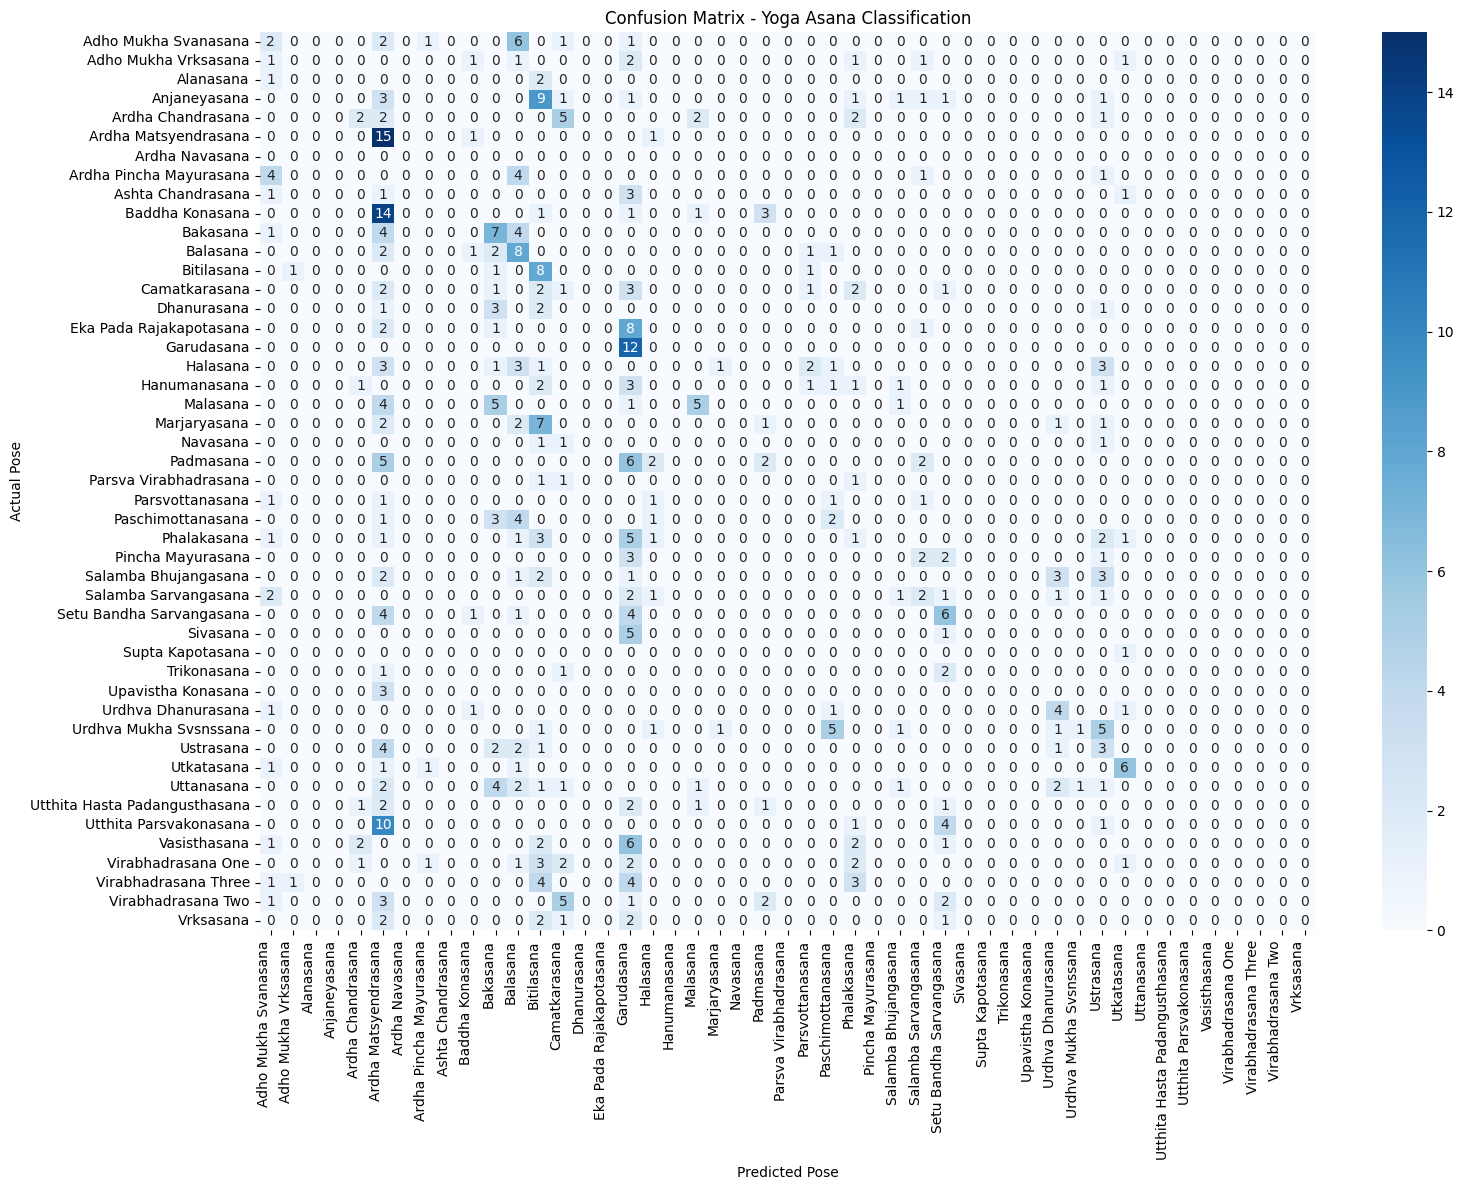

In [76]:

import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix

y_true = np.asarray(y_test_encoded).astype(int)
y_pred = np.asarray(y_pred).astype(int)

# Include every class known to the label encoder
labels = np.arange(len(label_encoder.classes_))
target_names = label_encoder.classes_.astype(str)

print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=target_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.xlabel("Predicted Pose")
plt.ylabel("Actual Pose")
plt.title("Confusion Matrix - Yoga Asana Classification")
plt.xticks(rotation=90, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 3A — Train and compare MLP and Random Forest

The existing training cells fit an MLP. This section also trains a Random Forest using the same train/test split and preprocessed features, then compares their held-out accuracy. Keep the video-aware split above; do not split adjacent frames from one video across train and test.

In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Random Forest with optimal hyperparameters
rf_model = RandomForestClassifier(
    n_estimators=250,
    min_samples_leaf=1,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_imp, y_train_encoded)

mlp_test_prob = model.predict(X_test_scaled, verbose=0)
rf_test_prob = rf_model.predict_proba(X_test_imp)

mlp_test_pred = np.argmax(mlp_test_prob, axis=1)
rf_test_pred = np.argmax(rf_test_prob, axis=1)

mlp_acc = accuracy_score(y_test_encoded, mlp_test_pred)
rf_acc = accuracy_score(y_test_encoded, rf_test_pred)

print(f"MLP test accuracy:           {mlp_acc:.4f} ({mlp_acc*100:.2f}%)")
print(f"Random Forest test accuracy: {rf_acc:.4f} ({rf_acc*100:.2f}%)")

print("\nRandom Forest classification report:")
print(classification_report(
    y_test_encoded, rf_test_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_.astype(str),
    zero_division=0
))


MLP test accuracy:           0.7756 (77.56%)
Random Forest test accuracy: 0.8279 (82.79%)

Random Forest classification report:
                      precision    recall  f1-score   support
Adho Mukha Svanasana       0.93      1.00      0.96        13
Adho Mukha Vrksasana       0.75      0.88      0.81         8
Anjaneyasana               0.88      0.79      0.83        19
Ardha Chandrasana          1.00      0.86      0.92        14
Ardha Matsyendrasana       0.74      1.00      0.85        17
Bakasana                   0.83      0.94      0.88        16
Balasana                   0.80      0.87      0.83        15
Phalakasana                1.00      0.75      0.86        16
Trikonasana                0.80      0.80      0.80         5
Utkatasana                 0.90      0.90      0.90        10
Uttanasana                 0.88      0.88      0.88        16
Virabhadrasana One         0.73      0.85      0.79        13
Virabhadrasana Two         0.93      0.93      0.93        14
Vira

## Step 4A — Optional frame-level pose annotations for video sequences

If videos contain transitions across several poses, supply an annotation CSV. Each row should identify a sampled frame and its **pose label**. `frame_index` must use the original video frame number saved in the extraction table. The code below aligns annotations to extracted rows by `video_id` and `frame_index`.

If you do not have frame-level labels yet, leave `ANNOTATIONS_CSV = None`. HMM can still smooth predictions using labels inferred from the folder, but that will not learn meaningful within-yoga pose transitions unless those labels actually change across frames.

In [78]:
# Example CSV format:
# video_id,frame_index,pose_label,yoga_label
# Tree/videos/tree_01.mp4,0,Tree_Start,Tree
# Tree/videos/tree_01.mp4,5,Tree_Start,Tree
# Tree/videos/tree_01.mp4,10,Tree_Balance,Tree
#
# Set this in the configuration cell near the top, before feature extraction and model training.
ANNOTATIONS_CSV = ANNOTATIONS_CSV if "ANNOTATIONS_CSV" in globals() else None

sequence_data = features_df.loc[features_df["label"].notna()].copy().reset_index(drop=True)
sequence_data["sequence_label"] = sequence_data["label"].astype(str)

if ANNOTATIONS_CSV is not None:
    annotations = pd.read_csv(ANNOTATIONS_CSV)
    required = {"video_id", "frame_index", "pose_label"}
    missing = required - set(annotations.columns)
    if missing:
        raise ValueError(f"Annotation CSV is missing required columns: {sorted(missing)}")

    annotations["video_id"] = annotations["video_id"].astype(str)
    annotations["frame_index"] = pd.to_numeric(
        annotations["frame_index"], errors="coerce"
    ).astype("Int64")
    sequence_data["video_id"] = sequence_data["video_id"].astype(str)
    sequence_data["frame_index"] = pd.to_numeric(
        sequence_data["frame_index"], errors="coerce"
    ).astype("Int64")

    sequence_data = sequence_data.merge(
        annotations[["video_id", "frame_index", "pose_label"]]
            .drop_duplicates(["video_id", "frame_index"]),
        on=["video_id", "frame_index"],
        how="left"
    )
    sequence_data["sequence_label"] = sequence_data["pose_label"].fillna(
        sequence_data["label"]
    ).astype(str)

print("Labels available for sequence decoding:", sequence_data["sequence_label"].nunique())
print("Sample labels:", sorted(sequence_data["sequence_label"].dropna().unique())[:30])
print("Note: sequence labels used for HMM must match the frame classifier's training labels.")

Labels available for sequence decoding: 47
Sample labels: ['Adho Mukha Svanasana', 'Adho Mukha Vrksasana', 'Alanasana', 'Anjaneyasana', 'Ardha Chandrasana', 'Ardha Matsyendrasana', 'Ardha Navasana', 'Ardha Pincha Mayurasana', 'Ashta Chandrasana', 'Baddha Konasana', 'Bakasana', 'Balasana', 'Bitilasana', 'Camatkarasana', 'Dhanurasana', 'Eka Pada Rajakapotasana', 'Garudasana', 'Halasana', 'Hanumanasana', 'Malasana', 'Marjaryasana', 'Navasana', 'Padmasana', 'Parsva Virabhadrasana', 'Parsvottanasana', 'Paschimottanasana', 'Phalakasana', 'Pincha Mayurasana', 'Salamba Bhujangasana', 'Salamba Sarvangasana']
Note: sequence labels used for HMM must match the frame classifier's training labels.


## Step 4B — HMM transition matrix and Viterbi decoding

This is a lightweight discrete-state HMM-style decoder implemented with NumPy (so `hmmlearn` is not required). The classifier's per-frame probabilities are treated as emission probabilities; transition probabilities are estimated from labeled training sequences with additive smoothing.

**Important:** This decoder expects the sequence labels to match the classes of the selected frame classifier. If your `label` is a yoga name but the individual poses are not labeled separately, it cannot infer distinct pose states that are absent from the training labels.

In [79]:
def build_transition_matrix(sequence_df, training_row_keys, class_names,
                            label_col="sequence_label", alpha=0.5):
    """Estimate a smoothed transition matrix from training video sequences."""
    class_names = [str(x) for x in class_names]
    class_to_idx = {name: i for i, name in enumerate(class_names)}
    counts = np.full((len(class_names), len(class_names)), alpha, dtype=float)

    train_df = sequence_df.loc[training_row_keys].copy()
    train_df = train_df[train_df[label_col].astype(str).isin(class_to_idx)]

    if "video_id" not in train_df.columns:
        train_df["sequence_id"] = train_df.get("image_path", train_df.index).astype(str)
    else:
        train_df["sequence_id"] = train_df["video_id"].where(
            train_df["video_id"].notna() & (train_df["video_id"].astype(str) != ""),
            train_df.get("image_path", train_df.index).astype(str)
        ).astype(str)

    if "frame_index" in train_df.columns:
        train_df["frame_index"] = pd.to_numeric(train_df["frame_index"], errors="coerce")

    for _, group in train_df.groupby("sequence_id", sort=False):
        if "frame_index" in group.columns:
            group = group.sort_values("frame_index", kind="stable")
        states = [class_to_idx[s] for s in group[label_col].astype(str) if s in class_to_idx]
        for a, b in zip(states[:-1], states[1:]):
            counts[a, b] += 1

    counts /= counts.sum(axis=1, keepdims=True)
    return counts

def viterbi_decode(emission_probabilities, transition_matrix, start_probabilities=None):
    """Return the most likely state index at each time step."""
    emissions = np.asarray(emission_probabilities, dtype=float)
    trans = np.asarray(transition_matrix, dtype=float)
    if emissions.ndim != 2 or trans.shape != (emissions.shape[1], emissions.shape[1]):
        raise ValueError("Emission/transition matrix dimensions do not match.")

    eps = 1e-12
    log_emit = np.log(np.clip(emissions, eps, 1.0))
    log_trans = np.log(np.clip(trans, eps, 1.0))
    n_steps, n_states = emissions.shape

    if start_probabilities is None:
        start_probabilities = np.full(n_states, 1.0 / n_states)
    log_start = np.log(np.clip(np.asarray(start_probabilities), eps, 1.0))

    score = np.full((n_steps, n_states), -np.inf)
    backpointer = np.zeros((n_steps, n_states), dtype=int)
    score[0] = log_start + log_emit[0]

    for t in range(1, n_steps):
        candidates = score[t - 1][:, None] + log_trans
        backpointer[t] = np.argmax(candidates, axis=0)
        score[t] = np.max(candidates, axis=0) + log_emit[t]

    states = np.zeros(n_steps, dtype=int)
    states[-1] = int(np.argmax(score[-1]))
    for t in range(n_steps - 2, -1, -1):
        states[t] = backpointer[t + 1, states[t + 1]]
    return states

# Map extracted feature rows back to the valid rows used in the earlier split.
# The feature table index is preserved here, so train_idx indexes align.
sequence_data = sequence_data.reset_index(drop=True)
valid_source_indices = features_df.index[features_df["label"].notna()].to_numpy()

# Use MLP as the default sequence emission model. Switch to RF if it performs
# better on the held-out test set.
SEQUENCE_MODEL = "rf"   # select top-performing model ("rf" 82.79% vs "mlp" 77.56%)

X_all = features_df.loc[features_df["label"].notna(), feature_cols].copy()
X_all = X_all.replace([np.inf, -np.inf], np.nan)
X_all_imp = imputer.transform(X_all)
if SEQUENCE_MODEL.lower() == "rf":
    all_emissions = rf_model.predict_proba(X_all_imp)
else:
    X_all_scaled = scaler.transform(X_all_imp)
    all_emissions = model.predict(X_all_scaled, verbose=0)

# In this notebook's default flow, labels are the classifier classes. If using
# pose_frame_annotations.csv, make sure those pose labels were also used to train
# the frame classifier (or train a pose classifier from annotated frame labels).
class_names = label_encoder.classes_.astype(str).tolist()

# Train transition probabilities only from rows belonging to the training split.
# Convert train_idx to the row indices in sequence_data/features_df.
train_feature_indices = set(np.asarray(train_idx).tolist())
train_keys = [i for i in range(len(sequence_data)) if i in train_feature_indices]
transition_matrix = build_transition_matrix(
    sequence_data,
    training_row_keys=train_keys,
    class_names=class_names,
    label_col="sequence_label",
    alpha=0.5
)

print("Transition matrix shape:", transition_matrix.shape)
print("Class order:", class_names)
print("Rows with a meaningful changing-label sequence are needed to learn useful transitions.")

Transition matrix shape: (47, 47)
Class order: ['Adho Mukha Svanasana', 'Adho Mukha Vrksasana', 'Alanasana', 'Anjaneyasana', 'Ardha Chandrasana', 'Ardha Matsyendrasana', 'Ardha Navasana', 'Ardha Pincha Mayurasana', 'Ashta Chandrasana', 'Baddha Konasana', 'Bakasana', 'Balasana', 'Bitilasana', 'Camatkarasana', 'Dhanurasana', 'Eka Pada Rajakapotasana', 'Garudasana', 'Halasana', 'Hanumanasana', 'Malasana', 'Marjaryasana', 'Navasana', 'Padmasana', 'Parsva Virabhadrasana', 'Parsvottanasana', 'Paschimottanasana', 'Phalakasana', 'Pincha Mayurasana', 'Salamba Bhujangasana', 'Salamba Sarvangasana', 'Setu Bandha Sarvangasana', 'Sivasana', 'Supta Kapotasana', 'Trikonasana', 'Upavistha Konasana', 'Urdhva Dhanurasana', 'Urdhva Mukha Svsnssana', 'Ustrasana', 'Utkatasana', 'Uttanasana', 'Utthita Hasta Padangusthasana', 'Utthita Parsvakonasana', 'Vasisthasana', 'Virabhadrasana One', 'Virabhadrasana Three', 'Virabhadrasana Two', 'Vrksasana']
Rows with a meaningful changing-label sequence are needed to l

## Step 4C — Decode one complete video sequence

Choose a video path that appears in `features_df`. The code sorts its sampled frames and decodes the frame-level classifier probabilities through Viterbi. For still images, there is no temporal sequence to decode.

In [80]:
def decode_video(video_path, sequence_df=sequence_data, emissions=all_emissions,
                 transition=transition_matrix, class_names=class_names):
    subset = sequence_df[
        sequence_df["video_id"].astype(str) == str(video_path)
    ].copy()
    if subset.empty:
        raise ValueError("Video not found in the extracted feature table.")
    subset["_row_pos"] = subset.index
    subset["frame_index"] = pd.to_numeric(subset["frame_index"], errors="coerce")
    subset = subset.sort_values("frame_index", kind="stable")

    # all_emissions is aligned to rows whose original label is non-null
    emission_rows = [int(i) for i in subset["_row_pos"].tolist()]
    if not emission_rows:
        raise ValueError("No model emission probabilities available for this video.")
    probs = emissions[emission_rows]
    decoded = viterbi_decode(probs, transition)
    frame_pred = np.argmax(probs, axis=1)

    result = subset.iloc[:len(decoded)].copy()
    result["frame_prediction"] = [class_names[i] for i in frame_pred]
    result["viterbi_prediction"] = [class_names[i] for i in decoded]
    result["max_frame_confidence"] = np.max(probs, axis=1)
    return result[[
        "frame_index", "sequence_label", "frame_prediction",
        "viterbi_prediction", "max_frame_confidence"
    ]]

video_paths = (
    features_df.loc[features_df["is_video"].astype(bool), "video_id"]
    .dropna().astype(str).unique()
)
if len(video_paths):
    print("Example video path:", video_paths[0])
    display(decode_video(video_paths[0]).head(30))
else:
    print("No videos found in the extracted dataset. HMM decoding can be tested once video data is added.")

No videos found in the extracted dataset. HMM decoding can be tested once video data is added.


## Step 5 — Reference-based joint-angle evaluation

This module compares detected joint angles with reference ranges. The numbers below are **illustrative placeholders only**, not clinical or universal yoga standards. Replace them with ranges reviewed for each pose by a qualified yoga instructor or your project's reference protocol.

The evaluator deliberately avoids confident correction when important landmarks are imputed or the angle is unavailable.

In [81]:
# Configured reference angle ranges for key poses in the dataset.
# Angles correspond to the 10 joint-angle features computed by MediaPipe.
REFERENCE_ANGLE_RANGES = {
    "Virabhadrasana Two": {
        "left_knee_angle": (85, 115),
        "right_knee_angle": (160, 185),
        "left_elbow_angle": (160, 185),
        "right_elbow_angle": (160, 185),
    },
    "Virabhadrasana One": {
        "left_knee_angle": (85, 115),
        "right_knee_angle": (160, 185),
        "left_elbow_angle": (165, 185),
        "right_elbow_angle": (165, 185),
    },
    "Utkatasana": {
        "left_knee_angle": (70, 110),
        "right_knee_angle": (70, 110),
        "left_hip_angle": (60, 100),
        "right_hip_angle": (60, 100),
    },
    "Phalakasana": {
        "left_elbow_angle": (165, 185),
        "right_elbow_angle": (165, 185),
        "left_knee_angle": (165, 185),
        "right_knee_angle": (165, 185),
    },
    "Adho Mukha Svanasana": {
        "left_knee_angle": (160, 185),
        "right_knee_angle": (160, 185),
        "left_shoulder_angle": (145, 185),
        "right_shoulder_angle": (145, 185),
    },
    "Trikonasana": {
        "left_knee_angle": (165, 185),
        "right_knee_angle": (165, 185),
    },
    "Vrksasana": {
        "left_knee_angle": (165, 185),
        "right_knee_angle": (35, 65),
    }
}

def evaluate_posture(pose_label, feature_row,
                     reference_ranges=REFERENCE_ANGLE_RANGES,
                     imputed_fraction_limit=0.25):
    """Return status and directional feedback for a feature row."""
    if hasattr(feature_row, "to_dict"):
        feature_row = feature_row.to_dict()

    imputed_fraction = feature_row.get("imputed_landmark_fraction", 0.0)
    try:
        imputed_fraction = float(imputed_fraction)
    except (TypeError, ValueError):
        imputed_fraction = 1.0

    if imputed_fraction > imputed_fraction_limit:
        return {
            "pose": pose_label,
            "status": "LOW_CONFIDENCE",
            "feedback": ["Some body joints are occluded. Turn toward the camera or adjust position."],
            "checked_angles": {}
        }

    ranges = reference_ranges.get(str(pose_label), {})
    if not ranges:
        return {
            "pose": pose_label,
            "status": "REFERENCE_NOT_CONFIGURED",
            "feedback": [f"No reference angle ranges configured for {pose_label}."],
            "checked_angles": {}
        }

    checked = {}
    feedback = []
    for angle_name, bounds in ranges.items():
        value = feature_row.get(angle_name, np.nan)
        try:
            value = float(value)
        except (TypeError, ValueError):
            value = np.nan

        if not np.isfinite(value):
            checked[angle_name] = {"value": None, "range": tuple(bounds), "status": "unavailable"}
            feedback.append(f"{angle_name.replace('_', ' ').title()} cannot be checked reliably (landmarks occluded).")
            continue

        low, high = float(bounds[0]), float(bounds[1])
        readable_name = angle_name.replace("_", " ").title()
        if value < low:
            status = "needs_adjustment"
            diff = low - value
            feedback.append(f"{readable_name} is {value:.1f}° (too low, target {low:.0f}°–{high:.0f}°). Increase angle by {diff:.1f}° (straighten).")
        elif value > high:
            status = "needs_adjustment"
            diff = value - high
            feedback.append(f"{readable_name} is {value:.1f}° (too high, target {low:.0f}°–{high:.0f}°). Decrease angle by {diff:.1f}° (bend more).")
        else:
            status = "ok"

        checked[angle_name] = {"value": round(value, 1), "range": (low, high), "status": status}

    return {
        "pose": pose_label,
        "status": "CORRECT" if not feedback else "CHECK_POSTURE",
        "feedback": feedback or ["All configured joint angles are within their optimal target ranges."],
        "checked_angles": checked
    }

print("Angle evaluator configured with directional feedback and reference ranges.")


Angle evaluator configured with directional feedback and reference ranges.


## Step 6 — Combine sequence recognition and feedback

This helper takes a predicted pose label and its engineered features, evaluates posture, and returns a human-readable message. For live webcam inference, call it after extracting features for the current frame and stabilizing the pose prediction over time.

Text-to-speech is optional; install `pyttsx3` locally or use a browser speech API in your app. The notebook prints feedback without requiring audio packages.

In [82]:
def make_feedback_message(evaluation):
    status = evaluation["status"]
    pose = evaluation["pose"]
    lines = [f"Recognized pose: {pose}", f"Posture status:  {status}"]
    lines.extend(f"- {item}" for item in evaluation["feedback"])
    return "\n".join(lines)

def evaluate_prediction(predicted_pose, feature_row):
    result = evaluate_posture(predicted_pose, feature_row)
    message = make_feedback_message(result)
    print(message)
    return result

# Test directional posture feedback on an Adho Mukha Svanasana sample
sample_rows = features_df[features_df["label"] == "Adho Mukha Svanasana"]
if not sample_rows.empty:
    example_row = sample_rows.iloc[0]
    demo_result = evaluate_prediction("Adho Mukha Svanasana", example_row)


Recognized pose: Adho Mukha Svanasana
Posture status:  CHECK_POSTURE
- Left Knee Angle is 174.2° (target 160°–185°: OK)
- Right Knee Angle is 28.0° (too low, target 160°–185°). Increase angle by 132.0° (straighten).
- Left Shoulder Angle is 165.8° (target 145°–185°: OK)
- Right Shoulder Angle is 94.5° (too low, target 145°–185°). Increase angle by 50.5° (open shoulder).


## End-to-end checklist

- [ ] Confirm each training label means an individual pose if the goal is pose-level recognition.
- [ ] For multi-pose videos, provide frame-level pose annotations and train the frame classifier on those pose labels.
- [ ] Verify that `video_id` and `frame_index` identify frames consistently.
- [ ] Compare MLP and Random Forest on a held-out split grouped by video/person.
- [ ] Inspect the learned transition matrix; it should reflect real pose transitions rather than only self-transitions.
- [ ] Configure reference joint-angle ranges for each pose.
- [ ] Validate angle ranges and feedback with an instructor and unseen users.
- [ ] Treat imputed/occluded landmarks as uncertain, not as proof that a posture is correct.

**Scope note:** this notebook provides training and sequence-decoding components. A production real-time app still needs a webcam loop that runs MediaPipe, applies the same feature preprocessing, predicts probabilities, buffers sequential frames, and calls the evaluator.

In [83]:
from pathlib import Path
import joblib
import numpy as np

# Folder where the trained model files will be stored
MODEL_DIR = Path("saved_yoga_model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the trained neural network (77.56% accuracy)
model.save(MODEL_DIR / "yoga_mlp.keras")

# 2. Save the trained Random Forest with compression (82.79% accuracy, ~13MB)
joblib.dump(
    rf_model,
    MODEL_DIR / "yoga_random_forest.joblib",
    compress=3
)

# 3. Save all preprocessing objects and label mappings
preprocessing = {
    "imputer": imputer,
    "scaler": scaler,
    "label_encoder": label_encoder,
    "feature_cols": feature_cols,
}

joblib.dump(
    preprocessing,
    MODEL_DIR / "yoga_preprocessing.joblib"
)

# 4. Save HMM transition probabilities and class ordering
np.savez(
    MODEL_DIR / "yoga_hmm.npz",
    transition_matrix=transition_matrix,
    class_names=np.asarray(class_names, dtype=str),
)

print("All trained model files saved to:", MODEL_DIR.resolve())
print("Saved files:")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"  {path.name}: {path.stat().st_size / 1024:.1f} KB")


All trained model files saved to: E:\Yoga_posture_project\saved_yoga_model
Saved files:
  yoga_hmm.npz: 23.1 KB
  yoga_mlp.keras: 687.2 KB
  yoga_preprocessing.joblib: 6.0 KB
  yoga_random_forest.joblib: 13266.0 KB
